# 7. Análisis final: rúbrica de modelos, pronóstico y calendario de siembra

Este capítulo cierra el proyecto con tres preguntas:

1. **¿Qué tan bueno es el modelo elegido frente a todos los que estudiamos?** Una rúbrica con pesos fijados de antemano califica a los siete modelos de lluvia en milímetros (tres tradicionales y cuatro de Machine Learning) en cada uno de los horizontes de 1 a 4 semanas.
2. **¿Qué pasaría si sembráramos maíz el 1 de enero?** Pronóstico de la temporada con el modelo híbrido y un balance hídrico del cultivo, en secano (solo lluvia, sin riego).
3. **¿Cuándo conviene sembrar y qué papel juegan los aguaceros?** Rendimiento esperado para cada fecha de siembra del año y valor de anticipar las semanas de aguacero.

Todas las cifras salen de los archivos que generó el capítulo 5 (`data/processed/hibrido_*.csv`) y de la serie diaria de NASA POWER 1981–2025.

In [2]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from src import config as cfg, hibrido as hb, cosecha as cs
plt.rcParams["figure.dpi"] = 110

PROC = cfg.DATA_PROCESSED
prueba = pd.read_csv(PROC / "hibrido_prueba.csv", parse_dates=["fecha"])
val = pd.read_csv(PROC / "hibrido_metricas_validacion.csv")
pru = pd.read_csv(PROC / "hibrido_metricas_prueba.csv")
MODELOS = ["Climatología", "Dummy (promedio)", "Persistencia", "SVR lineal", "Random forest", "Gradient boosting", "Híbrido"]
TIPO = {m: "Tradicional" for m in MODELOS[:3]} | {m: "Machine Learning" for m in MODELOS[3:]}
COLOR = {"Climatología": "#9AA9A3", "Dummy (promedio)": "#C9B79C", "Persistencia": "#B98B73", "SVR lineal": "#3A7CA5",
         "Random forest": "#D69E2E", "Gradient boosting": "#8E6CB0", "Híbrido": "#17332E"}
HORIZONTES = [1, 2, 3, 4]

## 7.1 Rúbrica de evaluación de los modelos

**Criterios y pesos, fijados antes de calcular los puntajes.** La rúbrica premia lo que necesita la finca: pronosticar bien la lluvia de cada semana (error), anticipar los aguaceros (lo que pidió la revisión del proyecto) y distinguir semanas secas. Cerca de la mitad del peso va a la validación 1981–2020 (unas 1.390 semanas, la evidencia más amplia) y la otra mitad a la prueba 2021–2025 (datos nuevos).

| Criterio | Métrica | Periodo | Peso |
|---|---|---|---|
| C1. Error de la lluvia semanal | MSE (menor es mejor) | Validación 1981–2020 | 25 % |
| C2. Error de la lluvia semanal | MSE | Prueba 2021–2025 | 15 % |
| C3. Detección de aguaceros | CSI: aciertos descontando falsas alarmas | Validación | 15 % |
| C4. Detección de aguaceros | CSI | Prueba | 15 % |
| C5. Distinguir semanas secas (< 10 mm) | AUC | Prueba | 10 % |
| C6. Distinguir semanas de aguacero (> P90) | AUC | Prueba | 10 % |
| C7. Mejora real frente a la climatología | Prueba de Diebold-Mariano | Prueba | 10 % |

**Cómo se convierte cada métrica en puntos (0 a 100).** En cada horizonte se compara cada modelo con **el mejor de los siete** en ese criterio:

- Error (C1, C2): $100 \times \text{MSE}_{\text{mejor}} / \text{MSE}_{\text{modelo}}$. Un modelo con el doble de error recibe 50.
- Aguaceros (C3, C4): $100 \times \text{CSI}_{\text{modelo}} / \text{CSI}_{\text{mejor}}$. Un modelo que nunca detecta aguaceros recibe 0.
- AUC (C5, C6): $100 \times (\text{AUC}_{\text{modelo}} - 0{,}5) / (\text{AUC}_{\text{mejor}} - 0{,}5)$. Adivinar al azar (AUC = 0,5) vale 0.
- C7: 100 si el modelo tiene un error significativamente **menor** que la climatología (p < 0,05), 0 si es significativamente **mayor**, 50 si no se distinguen (la climatología recibe 50).

Con esta escala, diferencias pequeñas dan puntajes parecidos: la rúbrica no exagera las diferencias.

**Niveles:** Excelente ≥ 90 · Bueno 75–90 · Aceptable 60–75 · Insuficiente < 60.

In [4]:
PESOS = {"C1 MSE validación": 25, "C2 MSE prueba": 15, "C3 CSI aguaceros validación": 15, "C4 CSI aguaceros prueba": 15,
         "C5 AUC semana seca": 10, "C6 AUC aguacero": 10, "C7 Mejor que climatología (DM)": 10}
assert sum(PESOS.values()) == 100

def metricas_prueba(h):
    P = prueba[prueba.h == h]; u = P.umbral.iloc[0]; filas = {}
    for m in MODELOS:
        pred = P[m].clip(lower=0).values
        ag = hb.tabla_aguaceros(P.y, pred, u)
        auc_s = roc_auc_score(P.y < 10, -pred) if np.ptp(pred) > 0 else 0.5
        auc_a = roc_auc_score(P.y > u, pred) if np.ptp(pred) > 0 else 0.5
        if m == "Climatología":
            dm = 50
        else:
            s, p = hb.diebold_mariano(P.y.values, P["Climatología"].values, pred, h)
            dm = 100 if (p < 0.05 and s > 0) else (0 if (p < 0.05 and s < 0) else 50)
        filas[m] = {"MSE prueba": hb.mse(P.y, pred), "CSI prueba": ag["CSI"], "POD prueba": ag["POD"], "FAR prueba": ag["FAR"],
                    "AUC seca": auc_s, "AUC aguacero": auc_a, "DM": dm}
    return pd.DataFrame(filas).T

def puntajes(h):
    V = val[val.h == h].set_index("modelo").loc[MODELOS]; T = metricas_prueba(h)
    S = pd.DataFrame(index=MODELOS)
    S["C1 MSE validación"] = 100 * V.MSE.min() / V.MSE
    S["C2 MSE prueba"] = 100 * T["MSE prueba"].min() / T["MSE prueba"]
    S["C3 CSI aguaceros validación"] = 100 * V.CSI / V.CSI.max()
    S["C4 CSI aguaceros prueba"] = 100 * T["CSI prueba"] / T["CSI prueba"].max()
    S["C5 AUC semana seca"] = 100 * (T["AUC seca"] - 0.5).clip(lower=0) / (T["AUC seca"].max() - 0.5)
    S["C6 AUC aguacero"] = 100 * (T["AUC aguacero"] - 0.5).clip(lower=0) / (T["AUC aguacero"].max() - 0.5)
    S["C7 Mejor que climatología (DM)"] = T["DM"].astype(float)
    S["Total"] = sum(S[c] * w for c, w in PESOS.items()) / 100
    return S.astype(float), V, T

def nivel(x):
    return "Excelente" if x >= 90 else "Bueno" if x >= 75 else "Aceptable" if x >= 60 else "Insuficiente"

PUNT = {h: puntajes(h) for h in HORIZONTES}
# Métricas originales (lo que se califica), a 1 semana como ejemplo
_, V1, T1 = PUNT[1]
pd.concat([V1[["MSE", "CSI"]].add_suffix(" validación"), T1[["MSE prueba", "CSI prueba", "POD prueba", "AUC seca", "AUC aguacero"]]], axis=1).astype(float).round(3)

,MSE validación,CSI validación,MSE prueba,CSI prueba,POD prueba,AUC seca,AUC aguacero
Climatología,662.895,0.057,1879.357,0.000,0.000,0.810,0.723
Dummy (promedio),885.659,0.000,2158.314,0.000,0.000,0.500,0.500
Persistencia,1105.886,0.218,2771.390,0.234,0.367,0.784,0.765
SVR lineal,583.344,0.134,1618.978,0.167,0.245,0.851,0.807
Random forest,586.406,0.151,1653.120,0.208,0.306,0.862,0.801
Gradient boosting,610.609,0.190,1624.726,0.277,0.531,0.856,0.801
Híbrido,582.799,0.206,1630.293,0.233,0.408,0.853,0.805


Métricas originales a 1 semana: es lo que la rúbrica convierte en puntos. Las de 2, 3 y 4 semanas se calculan igual.

In [6]:
tablas = []
for h in HORIZONTES:
    tablas.append(PUNT[h][0]["Total"].rename(f"{h} sem"))
TOT = pd.concat(tablas, axis=1)
CRIT = sum(PUNT[h][0][list(PESOS)] for h in HORIZONTES) / len(HORIZONTES)
FINAL = CRIT.round(1)
FINAL["Puntaje 1–4 sem"] = TOT.mean(axis=1).round(1)
FINAL["Nivel"] = FINAL["Puntaje 1–4 sem"].map(nivel)
FINAL.insert(0, "Tipo", pd.Series(TIPO))
FINAL = FINAL.sort_values("Puntaje 1–4 sem", ascending=False)
FINAL.columns = [c if c in ("Tipo", "Puntaje 1–4 sem", "Nivel") else f"{c} ({PESOS[c]} %)" for c in FINAL.columns]
FINAL.to_csv(PROC / "rubrica_final.csv")
pd.concat([PUNT[h][0].assign(h=h) for h in HORIZONTES]).rename_axis("modelo").to_csv(PROC / "rubrica_puntajes.csv")
FINAL

,Tipo,C1 MSE validación (25 %),C2 MSE prueba (15 %),C3 CSI aguaceros validación (15 %),C4 CSI aguaceros prueba (15 %),C5 AUC semana seca (10 %),C6 AUC aguacero (10 %),C7 Mejor que climatología (DM) (10 %),Puntaje 1–4 sem,Nivel
Híbrido,Machine Learning,100.0,98.8,98.7,92.9,98.0,99.2,62.5,94.5,Excelente
Gradient boosting,Machine Learning,96.5,97.8,85.7,100.0,98.4,96.7,62.5,92.4,Excelente
Random forest,Machine Learning,99.2,99.2,52.7,84.8,99.1,97.8,87.5,88.7,Bueno
SVR lineal,Machine Learning,99.7,99.2,47.7,59.8,96.9,99.6,100.0,85.6,Bueno
Persistencia,Tradicional,49.7,54.9,83.4,73.9,77.0,77.6,0.0,59.7,Insuficiente
Climatología,Tradicional,88.4,87.2,23.1,0.0,85.9,73.6,50.0,59.6,Insuficiente
Dummy (promedio),Tradicional,66.2,76.0,0.0,0.0,0.0,0.0,0.0,27.9,Insuficiente


**Tabla final de la rúbrica** (puntos de 0 a 100 por criterio, promedio de los horizontes de 1 a 4 semanas; entre paréntesis, el peso de cada criterio).

In [8]:
TOTH = TOT.round(1)
TOTH["Promedio"] = TOT.mean(axis=1).round(1)
TOTH["Puesto"] = TOTH["Promedio"].rank(ascending=False).astype(int)
TOTH = TOTH.sort_values("Promedio", ascending=False)
TOTH.to_csv(PROC / "rubrica_horizontes.csv")
print("Puntaje total por horizonte (0-100):")
TOTH

Puntaje total por horizonte (0-100):


,1 sem,2 sem,3 sem,4 sem,Promedio,Puesto
Híbrido,96.4,93.4,94.4,94.0,94.5,1
Gradient boosting,96.6,91.9,94.1,87.1,92.4,2
Random forest,91.1,87.0,87.7,89.2,88.7,3
SVR lineal,88.0,85.5,85.1,83.7,85.6,4
Persistencia,66.1,58.1,59.5,55.2,59.7,5
Climatología,59.7,59.4,59.7,59.6,59.6,6
Dummy (promedio),27.7,27.9,28.1,28.0,27.9,7


In [9]:
# ¿El resultado depende de los pesos? Se repite la rúbrica con dos esquemas alternativos
ALTERNATIVOS = {
    "Pesos iguales": {c: 100 / 7 for c in PESOS},
    "Solo prueba 2021-2025": {"C1 MSE validación": 0, "C2 MSE prueba": 30, "C3 CSI aguaceros validación": 0,
                              "C4 CSI aguaceros prueba": 30, "C5 AUC semana seca": 15, "C6 AUC aguacero": 15,
                              "C7 Mejor que climatología (DM)": 10},
    "Solo error (MSE)": {c: (50 if c.startswith(("C1", "C2")) else 0) for c in PESOS},
}
filas = {}
for nombre, W in ALTERNATIVOS.items():
    t = pd.concat([sum(PUNT[h][0][c] * w for c, w in W.items()) / 100 for h in HORIZONTES], axis=1).mean(axis=1)
    filas[nombre] = t.rank(ascending=False).astype(int)
filas["Pesos de la rúbrica"] = TOT.mean(axis=1).rank(ascending=False).astype(int)
SENS = pd.DataFrame(filas)[["Pesos de la rúbrica", "Pesos iguales", "Solo prueba 2021-2025", "Solo error (MSE)"]].sort_values("Pesos de la rúbrica")
SENS["Puesto promedio"] = SENS.mean(axis=1)
SENS.to_csv(PROC / "rubrica_sensibilidad.csv")
print("Puesto de cada modelo según el esquema de pesos:")
SENS

Puesto de cada modelo según el esquema de pesos:


,Pesos de la rúbrica,Pesos iguales,Solo prueba 2021-2025,Solo error (MSE),Puesto promedio
Híbrido,1,1,3,2,1.75
Gradient boosting,2,2,1,4,2.25
Random forest,3,3,2,3,2.75
SVR lineal,4,4,4,1,3.25
Persistencia,5,5,5,7,5.50
Climatología,6,6,6,5,5.75
Dummy (promedio),7,7,7,6,6.75


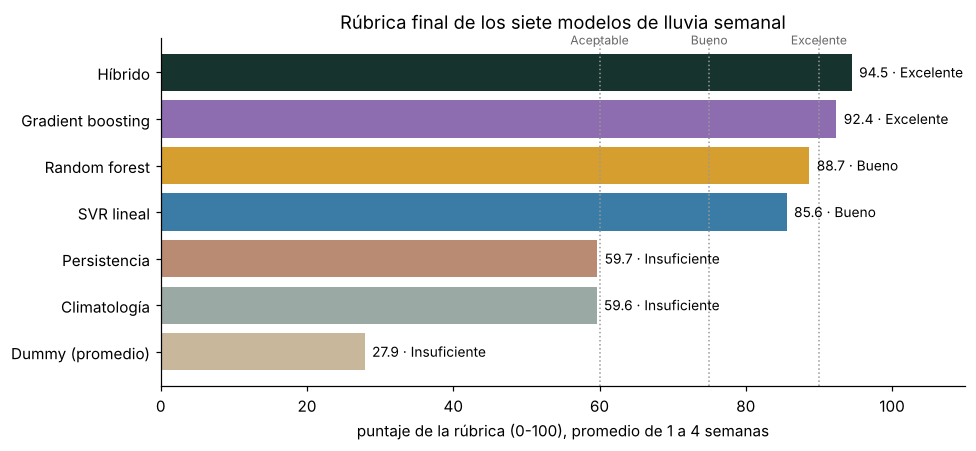

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.2))
orden = TOTH.index[::-1]
for i, m in enumerate(orden):
    ax.barh(i, TOTH.loc[m, "Promedio"], color=COLOR[m])
    ax.text(TOTH.loc[m, "Promedio"] + 1, i, f"{TOTH.loc[m, 'Promedio']:.1f} · {nivel(TOTH.loc[m, 'Promedio'])}", va="center", fontsize=9)
for x, lab in [(60, "Aceptable"), (75, "Bueno"), (90, "Excelente")]:
    ax.axvline(x, color="#999", ls=":", lw=1); ax.text(x, len(orden) - 0.4, lab, fontsize=8, color="#666", ha="center")
ax.set_yticks(range(len(orden))); ax.set_yticklabels(orden); ax.set_xlim(0, 110)
ax.set_xlabel("puntaje de la rúbrica (0-100), promedio de 1 a 4 semanas")
ax.set_title("Rúbrica final de los siete modelos de lluvia semanal")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Interpretación.** El **modelo híbrido obtiene el mayor puntaje de la rúbrica: 94,5 de 100, nivel Excelente**, y es el único que supera 93 puntos en los cuatro horizontes (96,4; 93,4; 94,4 y 94,0).

- **No gana en todos los criterios: es el más equilibrado.** En error (C1, C2) y en AUC (C5, C6) los cuatro modelos de ML están casi empatados, con 96 a 100 puntos. La diferencia está en los aguaceros. El SVR lineal tiene muy poco error, pero detecta pocos aguaceros (48 y 60 puntos en C3 y C4), y el random forest se queda en 53 puntos en la validación (C3). El híbrido conserva el bajo error del SVR y además detecta aguaceros como el mejor (99 y 93 puntos).
- **El gradient boosting (equivalente a XGBoost) queda segundo, con 92,4, también Excelente**, pero es inestable: gana por 0,2 puntos a 1 semana y cae a 87,1 a 4 semanas, porque su error en validación es el más alto de los modelos de ML.
- **Los tres métodos tradicionales quedan en nivel Insuficiente:** persistencia 59,7, climatología 59,6 y promedio (Dummy) 27,9. La climatología tiene un error razonable, pero no anticipa ningún aguacero de la prueba. La persistencia sí anticipa algunos, pero a costa del mayor error y de demasiadas falsas alarmas.
- **Punto débil del híbrido:** en C7 obtiene 62,5, porque su mejora frente a la climatología es significativa solo a 1 semana. A 2, 3 y 4 semanas el IC 95 % incluye el cero (capítulo 5).
- **¿Depende de los pesos?** Con pesos iguales, el híbrido sigue primero. Si se califica solo con la prueba 2021–2025, queda tercero (gana el gradient boosting), y si se califica solo con el error, segundo (gana el SVR). Por eso la elección no se hizo con la prueba ni con una sola métrica. Promediando los cuatro esquemas, el híbrido tiene el mejor puesto (1,75), frente a 2,25 del gradient boosting, 2,75 del random forest y 3,25 del SVR.

Nota: en la rúbrica los pronósticos negativos se llevan a 0 mm. Por eso el MSE de prueba del SVR (1.619) difiere un poco del que muestra el capítulo 5 (1.623).

## 7.2 Pronóstico de la temporada si se siembra el 1 de enero

**Cultivo:** maíz híbrido de 4 meses (120 días), con un rendimiento de **8 t/ha con riego al 100 %**. **Escenario:** secano, solo lluvia, sin riego.

**Modelo del cultivo** (archivo `src/cosecha.py`):

- **Demanda de agua** del cultivo: $ET_c = K_c \cdot ET_0$, con la curva de $K_c$ del maíz de FAO-56 (0,30 → 1,20 → 0,35) en etapas de 20, 35, 40 y 25 días (Allen et al., 1998).
- **Suelo:** balance diario del agua en la zona de raíces, que crecen de 0,3 a 1,0 m. Se supone un suelo franco arenoso con 120 mm de agua aprovechable por metro y una fracción de agotamiento sin estrés de 0,55 (FAO-56, tablas 19 y 22). Si el suelo se seca más allá de ese punto, el cultivo transpira menos ($ET_a < ET_c$). La lluvia que no cabe en el suelo se pierde.
- **Rendimiento** según la respuesta al agua por etapas de FAO-33 (Doorenbos y Kassam, 1979):

$$\frac{Y}{8\ \text{t/ha}} = \prod_{\text{etapas}} \Big[1 - K_y \Big(1 - \frac{ET_a}{ET_c}\Big)\Big]$$

con $K_y$ = 0,4 (establecimiento), 0,4 (crecimiento vegetativo), **1,5 (floración)**, 0,5 (llenado de grano) y 0,2 (maduración). La floración es la etapa en que la falta de agua más castiga el rendimiento.

**Pronóstico de la lluvia de la temporada.** Los datos llegan hasta el 31/12/2025, así que el pronóstico se emite para una siembra el **1 de enero de 2026**:

- Semanas 1 a 4: el **modelo híbrido** (capítulo 5).
- Semanas 5 a 17: el modelo no tiene habilidad a ese plazo, así que se usan como escenarios las lluvias reales de cada año 1981–2025 desde el 29 de enero (predicción por conjuntos con trazas históricas, ESP; Day, 1985).
- La humedad inicial del suelo se calcula con la lluvia y la $ET_0$ reales de noviembre y diciembre de 2025.

Para otro año, el mismo cálculo se repite con los datos descargados hasta el día anterior a la siembra.

In [13]:
df = pd.read_csv(PROC / cfg.ARCHIVO_DATOS, parse_dates=["fecha"])
serie = cs.preparar_serie(df[df.punto == cfg.PUNTO_OBJETIVO].set_index("fecha").sort_index())   # ET0 de 1981-1983 completada
pron = pd.read_csv(PROC / "pronostico_lluvia_semanal.csv")
SIEMBRA = serie.index.max() + pd.Timedelta(days=1)
previa = serie.loc[SIEMBRA - pd.Timedelta(days=60): SIEMBRA - pd.Timedelta(days=1)]
Dr0 = cs.humedad_inicial(previa.PRECTOTCORR.values, previa.ET0.values)
print(f"Siembra: {SIEMBRA:%d/%m/%Y} · lluvia de los 60 días previos: {previa.PRECTOTCORR.sum():.0f} mm · "
      f"agua faltante en el suelo al sembrar: {Dr0:.0f} de {cs.SUELO['TAW_mm_m'] * cs.SUELO['Zr_ini']:.0f} mm")
p4 = pron[pron.semana <= 4][["semana", "P_q500", "P_q950", "P_q975"]].rename(columns={"P_q500": "mediana (mm)", "P_q950": "percentil 95 (mm)", "P_q975": "percentil 97,5 (mm)"})
print("Pronóstico del híbrido para las semanas 1 a 4:")
p4.round(1)

Siembra: 01/01/2026 · lluvia de los 60 días previos: 96 mm · agua faltante en el suelo al sembrar: 19 de 36 mm
Pronóstico del híbrido para las semanas 1 a 4:


,semana,mediana (mm),percentil 95 (mm),"percentil 97,5 (mm)"
0,1,0.0,50.8,75.7
1,2,0.0,50.7,77.3
2,3,0.0,51.1,79.1
3,4,0.0,49.3,74.0


In [14]:
def temporada(anio_traza, caso):
    # Semanas 1-4: pronóstico del híbrido repartido por igual en los 7 días; desde el día 29: lluvia real del año de la traza
    inicio_traza = pd.Timestamp(f"{anio_traza}-01-01")
    traza = serie.loc[inicio_traza: inicio_traza + pd.Timedelta(days=cs.DIAS - 1)]
    if len(traza) < cs.DIAS:
        return None
    P = traza.PRECTOTCORR.values.copy()
    if caso != "traza":
        P[:28] = np.repeat(pron.set_index("semana").loc[[1, 2, 3, 4], caso].values / 7, 7)
    sim = cs.simular(P, traza.ET0.values, Dr0)
    y, det = cs.rendimiento(sim)
    return {"traza": anio_traza, "caso": caso, "rendimiento": y, "lluvia": sim.P.sum(), "ETc": sim.ETc.sum(), "ETa": sim.ETa.sum(),
            "perdida": sim.perdida.sum(), "floracion": det.loc[2, "ETa/ETc"]}

ENE = pd.DataFrame([r for a in range(1981, 2026) for c in ("P_q500", "P_q950") if (r := temporada(a, c))])
ENE.to_csv(PROC / "siembra_enero_escenarios.csv", index=False)
res = ENE.groupby("caso").agg(rend_medio=("rendimiento", "mean"), p10=("rendimiento", lambda v: v.quantile(0.1)),
                               p90=("rendimiento", lambda v: v.quantile(0.9)), prob_menos_2t=("rendimiento", lambda v: (v < 2).mean()),
                               lluvia=("lluvia", "mean"), ETc=("ETc", "mean"), ETa=("ETa", "mean"), agua_floracion=("floracion", "mean"))
res.index = ["Semanas 1-4 = mediana del híbrido", "Semanas 1-4 = percentil 95 del híbrido (caso húmedo)"]
mm_ = ENE[ENE.caso == "P_q500"]
_def = (mm_.ETc - mm_.ETa).mean()
print(f"Riego que haría falta para llegar a 8 t/ha (ETc - ETa, caso mediana): {_def:.0f} mm = " + f"{10 * _def:,.0f}".replace(",", ".") + " m³ por hectárea")
print(f"Siembra el {SIEMBRA:%d/%m/%Y}, maíz en secano, {ENE.traza.nunique()} escenarios de lluvia (años 1981-2025):")
res.round(2)

Riego que haría falta para llegar a 8 t/ha (ETc - ETa, caso mediana): 489 mm = 4.886 m³ por hectárea
Siembra el 01/01/2026, maíz en secano, 45 escenarios de lluvia (años 1981-2025):


,rend_medio,p10,p90,prob_menos_2t,lluvia,ETc,ETa,agua_floracion
Semanas 1-4 = mediana del híbrido,0.00,0.0,0.0,1.0,48.85,538.91,50.31,0.04
Semanas 1-4 = percentil 95 del híbrido (caso húmedo),0.02,0.0,0.0,1.0,250.73,538.91,169.35,0.11


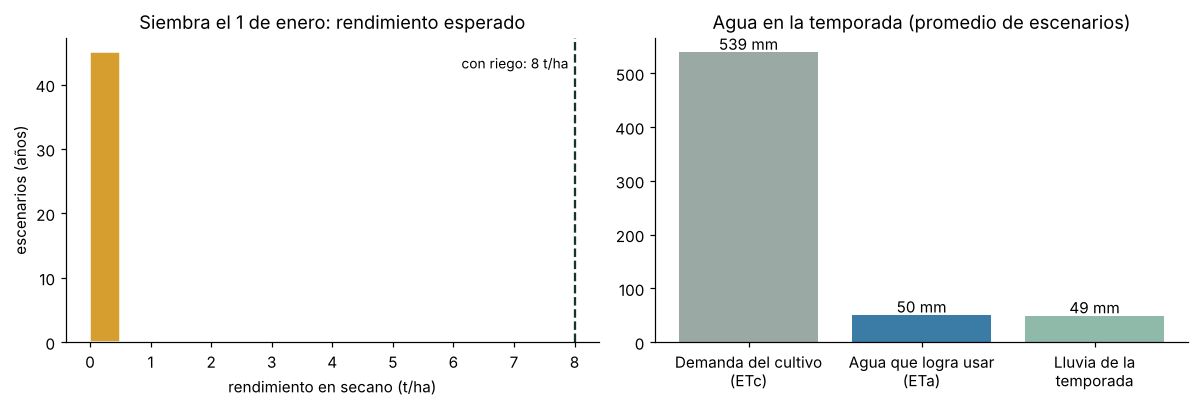

In [15]:
m = ENE[ENE.caso == "P_q500"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(m.rendimiento, bins=np.arange(0, 8.5, 0.5), color="#D69E2E", edgecolor="white")
ax[0].axvline(8, color="#17332E", ls="--"); ax[0].text(7.9, ax[0].get_ylim()[1] * 0.9, "con riego: 8 t/ha", ha="right", fontsize=9)
ax[0].set_xlabel("rendimiento en secano (t/ha)"); ax[0].set_ylabel("escenarios (años)"); ax[0].set_title("Siembra el 1 de enero: rendimiento esperado")
ax[1].bar(["Demanda del cultivo\n(ETc)", "Agua que logra usar\n(ETa)", "Lluvia de la\ntemporada"], [m.ETc.mean(), m.ETa.mean(), m.lluvia.mean()],
          color=["#9AA9A3", "#3A7CA5", "#8FB9A8"])
for i, v in enumerate([m.ETc.mean(), m.ETa.mean(), m.lluvia.mean()]):
    ax[1].text(i, v + 5, f"{v:.0f} mm", ha="center")
ax[1].set_title("Agua en la temporada (promedio de escenarios)")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Interpretación.** Sembrar maíz en secano el 1 de enero es **perder la cosecha**:

- El híbrido pronostica una mediana de **0 mm en cada una de las semanas 1 a 4**. Incluso en el caso húmedo (percentil 95) llueven unos 50 mm por semana.
- En los 45 escenarios, el rendimiento medio es **0,00 t/ha** y el **100 %** de los años da menos de 2 t/ha. En el caso húmedo apenas sube a 0,02 t/ha.
- La razón es el balance de agua: el cultivo necesita unos **539 mm** en 120 días y la temporada trae unos **49 mm**. El maíz solo logra usar 50 mm de agua y la floración (semanas 9 a 11) cae entre finales de febrero y mediados de marzo, en plena temporada seca.
- Para obtener las 8 t/ha con riego habría que aplicar unos **489 mm**, es decir, **4.886 m³ de agua por hectárea**. Esa agua tendría que salir del almacenamiento de la finca (capítulo 6).

**Conclusión:** en enero solo tiene sentido sembrar con riego completo. En secano, la decisión correcta es no sembrar.

## 7.3 ¿Cuándo sembrar? Rendimiento esperado según la fecha de siembra

Se simula una siembra el día 1 y el día 15 de cada mes, en cada uno de los años 1981–2025, con la lluvia y la $ET_0$ reales de cada año. Para cada fecha se calcula el rendimiento medio en secano, el rango del 80 % de los años (percentiles 10 y 90) y la probabilidad de perder la cosecha (menos de 2 t/ha, la cuarta parte del potencial).

In [18]:
filas = []
for mes in range(1, 13):
    for dia in (1, 15):
        for a in range(1981, 2026):
            r = cs.simular_siembra(serie, f"{a}-{mes:02d}-{dia:02d}")
            if r:
                filas.append({"mes": mes, "dia": dia, "anio": a, "rendimiento": r["rendimiento"], "lluvia": r["lluvia"],
                              "perdida": r["perdida"], "ETc": r["ETc"], "ETa": r["ETa"]})
CAL = pd.DataFrame(filas)
MES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
CALR = CAL.groupby(["mes", "dia"]).agg(rend_medio=("rendimiento", "mean"), p10=("rendimiento", lambda v: v.quantile(0.1)),
                                        p90=("rendimiento", lambda v: v.quantile(0.9)), prob_perder=("rendimiento", lambda v: (v < 2).mean()),
                                        lluvia=("lluvia", "mean"), lluvia_perdida=("perdida", "mean"), anios=("anio", "count")).reset_index()
CALR.insert(0, "siembra", [f"{d} {MES[m - 1]}" for m, d in zip(CALR.mes, CALR.dia)])
CALR.to_csv(PROC / "calendario_siembra.csv", index=False)
mejor = CALR.loc[CALR.rend_medio.idxmax()]
print(f"Mejor fecha: {mejor.siembra} · {mejor.rend_medio:.2f} t/ha en promedio ({mejor.rend_medio / cs.YMAX:.0%} del potencial) · "
      f"perder la cosecha: {mejor.prob_perder:.0%} de los años")
print(f"1 de enero: {CALR.iloc[0].rend_medio:.2f} t/ha · perder la cosecha: {CALR.iloc[0].prob_perder:.0%} de los años")
CALR.drop(columns=["mes", "dia"]).set_index("siembra").round(2)

Mejor fecha: 15 ago · 6.90 t/ha en promedio (86% del potencial) · perder la cosecha: 7% de los años
1 de enero: 0.00 t/ha · perder la cosecha: 100% de los años


,rend_medio,p10,p90,prob_perder,lluvia,lluvia_perdida,anios
siembra,,,,,,,
1 ene,0.00,0.00,0.00,1.00,55.16,2.72,45
15 ene,0.00,0.00,0.00,1.00,88.11,1.62,45
1 feb,0.02,0.00,0.00,1.00,175.68,24.49,45
15 feb,0.09,0.00,0.15,0.98,224.54,32.47,45
1 mar,0.73,0.00,2.21,0.82,274.76,36.78,45
15 mar,1.50,0.00,4.55,0.71,321.43,50.84,45
1 abr,2.70,0.00,6.07,0.47,376.28,77.75,45
15 abr,3.43,0.00,7.67,0.44,416.24,111.40,45
1 may,3.68,0.00,7.99,0.42,461.11,153.38,45


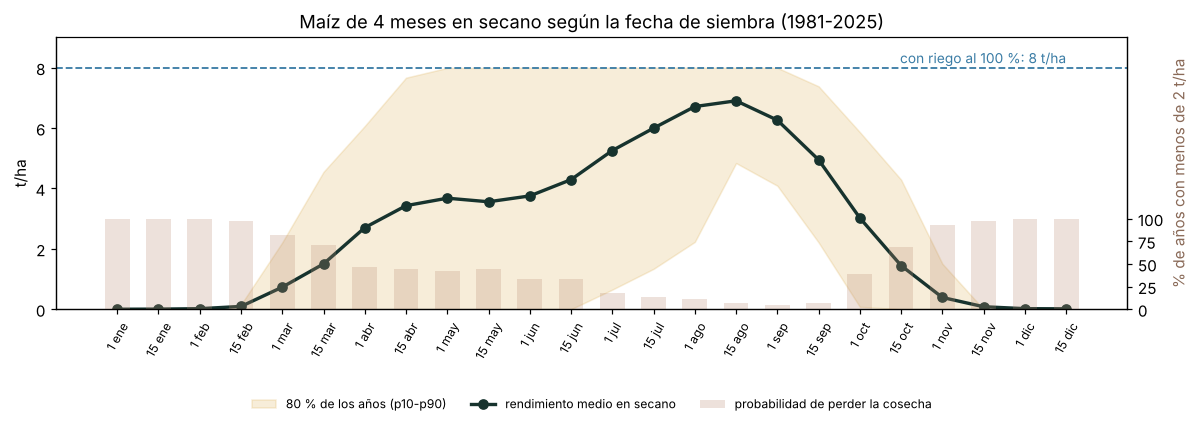

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(CALR))
ax.fill_between(x, CALR.p10, CALR.p90, color="#D69E2E", alpha=0.18, label="80 % de los años (p10-p90)")
ax.plot(x, CALR.rend_medio, "o-", color="#17332E", lw=2.2, label="rendimiento medio en secano")
ax.axhline(cs.YMAX, color="#3A7CA5", ls="--", lw=1.2); ax.text(len(CALR) - 1, cs.YMAX + 0.15, "con riego al 100 %: 8 t/ha", ha="right", color="#3A7CA5", fontsize=9)
ax2 = ax.twinx(); ax2.bar(x, CALR.prob_perder * 100, color="#B98B73", alpha=0.25, width=0.6, label="probabilidad de perder la cosecha")
ax2.set_ylim(0, 300); ax2.set_yticks([0, 25, 50, 75, 100]); ax2.set_ylabel("% de años con menos de 2 t/ha", color="#8a6a58")
ax.set_xticks(x); ax.set_xticklabels(CALR.siembra, rotation=60, fontsize=8); ax.set_ylim(0, 9)
ax.set_ylabel("t/ha"); ax.set_title("Maíz de 4 meses en secano según la fecha de siembra (1981-2025)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8, frameon=False)
ax.spines[["top"]].set_visible(False)
plt.tight_layout(); plt.show()

**Interpretación.**

- **La mejor fecha es el 15 de agosto:** 6,90 t/ha en promedio, el 86 % del potencial con riego, y solo el 7 % de los años con pérdida de la cosecha. Aun en un mal año (percentil 10) se cosechan 4,84 t/ha.
- **La ventana recomendada va del 15 de julio al 1 de septiembre:** entre 6,00 y 6,90 t/ha, con pérdida en el 4 % al 13 % de los años. La siembra del 1 de septiembre es la de menor riesgo (4 %).
- **Por qué funciona:** sembrando el 15 de agosto, la floración cae del 9 al 28 de octubre (días 56 a 75), en los meses más lluviosos del año (capítulo 2). La cosecha llega a mediados de diciembre, con tiempo seco para secar el grano.
- **Primera temporada (abril a junio): riesgosa.** Rinde entre 2,70 y 4,29 t/ha y se pierde en el 33 % al 47 % de los años, porque el veranillo de mitad de año puede coincidir con la floración. Solo conviene con riego de apoyo.
- **De noviembre a marzo no se debe sembrar en secano:** el rendimiento es de 1,50 t/ha o menos y la cosecha se pierde en el 71 % al 100 % de los años.

**Beneficio:** pasar la siembra del 1 de enero al 15 de agosto significa pasar de 0 a 6,90 t/ha. Ese es el valor de usar el pronóstico y la climatología para decidir cuándo sembrar.

## 7.4 Los aguaceros y la decisión

Tres preguntas: ¿cuánta de la lluvia útil llega en semanas de aguacero?, ¿cuánta se pierde porque el suelo ya no puede guardarla?, y ¿qué modelo avisa de esas semanas con anticipación?

In [22]:
U = prueba.umbral.iloc[0]          # umbral de aguacero: percentil 90 de la lluvia semanal de entrenamiento
def aguaceros_temporada(fecha):
    r = cs.simular_siembra(serie, fecha)
    sim = r["sim"].assign(semana=lambda d: d.dia // 7)
    sem = sim.groupby("semana").agg(P=("P", "sum"), perdida=("perdida", "sum"))
    ag = sem.P > U
    flor = sim.iloc[55:75]           # floración: días 56 a 75
    flor_ag = (flor.groupby(flor.dia // 7).P.sum() > U).any()
    return {"anio": pd.Timestamp(fecha).year, "rendimiento": r["rendimiento"], "lluvia": sem.P.sum(), "lluvia_aguacero": sem.P[ag].sum(),
            "semanas_aguacero": int(ag.sum()), "perdida": sem.perdida.sum(), "perdida_aguacero": sem.perdida[ag].sum(), "aguacero_floracion": flor_ag}

FECHA_MEJOR = f"{int(mejor.dia)}-{int(mejor.mes):02d}"
AG = pd.DataFrame([aguaceros_temporada(f"{a}-{int(mejor.mes):02d}-{int(mejor.dia):02d}") for a in range(1981, 2026)])
AG.assign(siembra=mejor.siembra).to_csv(PROC / "aguaceros_mejor_fecha.csv", index=False)
tot = AG[["lluvia", "lluvia_aguacero", "perdida", "perdida_aguacero"]].mean()
print(f"Siembra el {mejor.siembra} (mejor fecha), promedio de 1981-2025; aguacero = semana con más de {U:.0f} mm")
print(f"  Semanas de aguacero en la temporada: {AG.semanas_aguacero.mean():.1f} de 17")
print(f"  Lluvia de la temporada: {tot.lluvia:.0f} mm, de la cual {tot.lluvia_aguacero:.0f} mm ({tot.lluvia_aguacero / tot.lluvia:.0%}) llega en semanas de aguacero")
print(f"  Lluvia que el suelo no puede guardar: {tot.perdida:.0f} mm; en semanas de aguacero: {tot.perdida_aguacero:.0f} mm "
      f"({tot.perdida_aguacero / tot.perdida:.0%} de lo perdido) = {10 * tot.perdida_aguacero:,.0f} m³ por hectárea".replace(",", "."))
con, sin = AG[AG.aguacero_floracion], AG[~AG.aguacero_floracion]
print(f"  Rendimiento medio con aguacero en floración: {con.rendimiento.mean():.2f} t/ha ({len(con)} años); sin: {sin.rendimiento.mean():.2f} t/ha ({len(sin)} años)")

Siembra el 15 ago (mejor fecha), promedio de 1981-2025; aguacero = semana con más de 52 mm
  Semanas de aguacero en la temporada: 3.4 de 17
  Lluvia de la temporada: 566 mm, de la cual 293 mm (52%) llega en semanas de aguacero
  Lluvia que el suelo no puede guardar: 250 mm; en semanas de aguacero: 182 mm (73% de lo perdido) = 1.818 m³ por hectárea
  Rendimiento medio con aguacero en floración: 7.50 t/ha (26 años); sin: 6.08 t/ha (19 años)


In [23]:
# ¿Quién avisa de los aguaceros de la temporada recomendada (julio a noviembre) con 1 a 4 semanas de anticipación? Prueba 2021-2025
filas = []
for h in HORIZONTES:
    P = prueba[(prueba.h == h)]
    obj = P.fecha + pd.Timedelta(days=7 * h - 4)                      # centro de la semana pronosticada
    P = P[obj.dt.month.between(7, 11)]
    for m in MODELOS:
        a = hb.tabla_aguaceros(P.y, P[m].clip(lower=0), U)
        filas.append({"h": h, "modelo": m, "aguaceros": a["aguaceros"], "avisados": a["detectados"], "POD": a["POD"], "falsas alarmas": a["falsas_alarmas"]})
AV = pd.DataFrame(filas)
AV.to_csv(PROC / "aguaceros_temporada.csv", index=False)
print("Aguaceros de julio a noviembre 2021-2025 avisados con anticipación (porcentaje de los ocurridos):")
AV.pivot(index="modelo", columns="h", values="POD").loc[MODELOS].rename(columns=lambda h: f"{h} sem").map(lambda v: f"{v:.0%}")

Aguaceros de julio a noviembre 2021-2025 avisados con anticipación (porcentaje de los ocurridos):


h,1 sem,2 sem,3 sem,4 sem
modelo,,,,
Climatología,0%,0%,0%,0%
Dummy (promedio),0%,0%,0%,0%
Persistencia,36%,30%,42%,33%
SVR lineal,33%,39%,39%,30%
Random forest,45%,58%,70%,55%
Gradient boosting,61%,64%,64%,70%
Híbrido,58%,67%,79%,67%


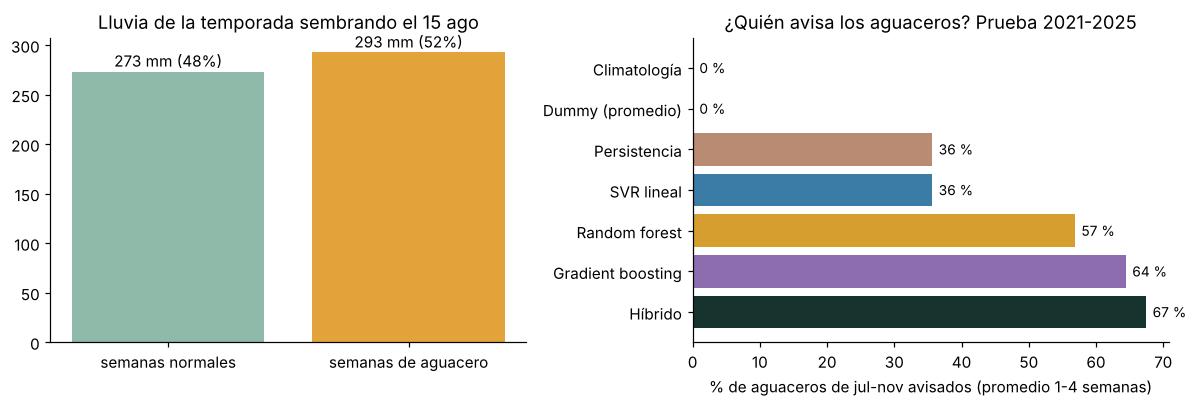

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
v = [tot.lluvia - tot.lluvia_aguacero, tot.lluvia_aguacero]
ax[0].bar(["semanas normales", "semanas de aguacero"], v, color=["#8FB9A8", "#E3A33B"])
for i, x in enumerate(v): ax[0].text(i, x + 5, f"{x:.0f} mm ({x / sum(v):.0%})", ha="center")
ax[0].set_title(f"Lluvia de la temporada sembrando el {mejor.siembra}")
pv = AV.pivot(index="modelo", columns="h", values="POD").loc[MODELOS].mean(axis=1) * 100
ax[1].barh(pv.index, pv.values, color=[COLOR[m] for m in pv.index])
for i, x in enumerate(pv.values): ax[1].text(x + 1, i, f"{x:.0f} %", va="center", fontsize=9)
ax[1].set_xlabel("% de aguaceros de jul-nov avisados (promedio 1-4 semanas)"); ax[1].set_title("¿Quién avisa los aguaceros? Prueba 2021-2025")
ax[1].invert_yaxis()
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Interpretación. Los aguaceros son la mitad del agua de la temporada.**

- **Pocas semanas, mucha agua.** Sembrando el 15 de agosto, en promedio solo 3,4 de las 17 semanas son de aguacero, pero traen **293 de los 566 mm (52 %)** de la lluvia de la temporada.
- **La mayor parte del agua perdida se pierde en esas semanas.** El suelo no puede guardar 250 mm de la lluvia de la temporada, y el **73 %** de esa pérdida (182 mm) ocurre en las semanas de aguacero. Son unos **1.818 m³ por hectárea** que escurren o se infiltran fuera del alcance de las raíces.
- **Coincidir con la floración vale 1,4 t/ha.** Los años con al menos un aguacero en la floración rinden **7,50 t/ha** (26 años), frente a **6,08 t/ha** (19 años) sin aguacero en esa etapa.

**Quién avisa de los aguaceros de julio a noviembre (prueba 2021–2025):**

- La climatología y el promedio no avisan **ninguno**: por construcción, nunca pronostican una semana de más de 52 mm.
- La persistencia avisa el 30–42 % y el SVR lineal el 30–39 %.
- El random forest avisa el 45–70 % y el gradient boosting el 61–70 %.
- El **híbrido avisa el 58–79 %** (67 % en promedio, el más alto), con 1 a 4 semanas de anticipación.

**Cómo ayuda a decidir mejor.** Con el aviso del híbrido, la finca puede:

1. **Preparar la captación** (limpiar canales, dejar espacio en el reservorio) para guardar parte de esos 1.818 m³/ha. Con esa agua se puede regar la floración en los años en que no llueve fuerte, o apoyar una primera temporada.
2. **Ajustar la fecha de siembra dentro de la ventana.** Sembrar justo antes de lluvias anunciadas asegura el establecimiento. Si el suelo ya está saturado, se puede esperar a que pase el aguacero para no perder la semilla por encharcamiento.
3. **Programar la fertilización.** No abonar antes de un aguacero anunciado, para que la lluvia no lave el nitrógeno.
4. **Decidir si hace falta regar la floración.** Si el pronóstico no muestra aguaceros para octubre, ese es el momento de usar el agua guardada.

**Límites que hay que reconocer:**

- Cerca de dos de cada tres alertas de aguacero no se cumplen (FAR de 0,63 a 0,65; capítulo 5). Por eso las alertas sirven para **acciones de bajo costo y reversibles** (preparar el reservorio, aplazar el abono), no para decisiones irreversibles.
- El modelo del cultivo no simula el daño por exceso de agua (encharcamiento).

## 7.5 Conclusión del proyecto

1. **Modelo elegido:** el híbrido SVR + random forest. Es el primero de la rúbrica (94,5 de 100, Excelente) entre siete modelos y el único por encima de 93 puntos en los cuatro horizontes. Frente a los otros modelos de Machine Learning tiene un error parecido; su ventaja es que anticipa más aguaceros. Frente a los métodos tradicionales es claramente superior.
2. **Siembra el 1 de enero en secano:** 0 t/ha. Solo es viable con riego completo, unos 4.886 m³ por hectárea.
3. **Mejor época para sembrar maíz de 4 meses en secano:** del 15 de julio al 1 de septiembre, con el 15 de agosto como mejor fecha (6,90 t/ha, el 86 % del potencial con riego).
4. **Los aguaceros son la mitad del agua de esa temporada.** El híbrido es el modelo que más los anticipa (67 % de los aguaceros de julio a noviembre en la prueba, frente a 0 % de la climatología). Ese aviso permite captar agua, ajustar la fecha de siembra y la fertilización, y decidir cuándo regar la floración.